# Homework 6

Harsh Toshniwal

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from imblearn.ensemble import BalancedRandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.model_selection import cross_validate
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.svm import SVC

## 1(a) Load the APS Failure data

In [2]:
# The first 20 lines of each csv are a license header, and missing values are written as 'na'
train = pd.read_csv('Homework 6 Data/aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv('Homework 6 Data/aps_failure_test_set.csv', skiprows=20, na_values='na')
train.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [3]:
print('Train shape:', train.shape)
print('Test shape:', test.shape)

Train shape: (60000, 171)
Test shape: (16000, 171)


In [4]:
# Change the class column from neg/pos to 0/1
train['class'] = train['class'].map({'neg': 0, 'pos': 1})
test['class'] = test['class'].map({'neg': 0, 'pos': 1})

train['class'].value_counts()

class
0    59000
1     1000
Name: count, dtype: int64

In [5]:
features = list(train.columns)
features.remove('class')
len(features)

170

## 1(b) Data Preparation

### i. Missing values

In [6]:
# Fraction of missing values in each feature
missing = train[features].isna().mean().sort_values(ascending=False)
missing.head(15)

br_000    0.821067
bq_000    0.812033
bp_000    0.795667
bo_000    0.772217
ab_000    0.772150
cr_000    0.772150
bn_000    0.733483
bm_000    0.659150
bl_000    0.454617
bk_000    0.383900
cg_000    0.247683
ch_000    0.247683
cf_000    0.247683
co_000    0.247683
ad_000    0.247683
dtype: float64

In [7]:
print('Features with at least one missing value:', (missing > 0).sum())
print('Features with more than 50% missing:', (missing > 0.5).sum())
print('Training rows with no missing values:', train.dropna().shape[0], 'out of', train.shape[0])

Features with at least one missing value: 169
Features with more than 50% missing: 8
Training rows with no missing values: 591 out of 60000


Common imputation techniques:

- Deletion: drop rows with missing values, or drop mostly-missing features.
- Simple imputation: fill with the feature's mean, median, mode, or a constant.
- Model-based: KNN imputation, or iterative imputation (MICE).
- Missing indicators: add a 0/1 column marking where a value was missing.
- Models that handle missing values themselves (e.g. XGBoost).

**What I picked and why**

Median imputation. Deletion is not an option since only 591 of 60,000 rows are complete. The features are very skewed counters, so the median is a better typical value than the mean. KNN and MICE would be very slow at this size. Following footnote 1, train is filled with train medians and test with test medians.

In [8]:
train_medians = train[features].median()
test_medians = test[features].median()

train[features] = train[features].fillna(train_medians)
test[features] = test[features].fillna(test_medians)

In [9]:
print('Missing values left in train:', train.isna().sum().sum())
print('Missing values left in test:', test.isna().sum().sum())

Missing values left in train: 0
Missing values left in test: 0


### ii. Coefficient of variation

In [10]:
cv = train[features].std() / train[features].mean()
cv = cv.sort_values(ascending=False)
cv

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
             ...    
bo_000      0.792383
bp_000      0.753392
bq_000      0.718534
br_000      0.689112
cd_000      0.000000
Length: 170, dtype: float64

In [11]:
# cd_000 has the same value in every row, so its standard deviation and CV are 0
print(train['cd_000'].unique())

[1209600.]


### iii. Correlation matrix

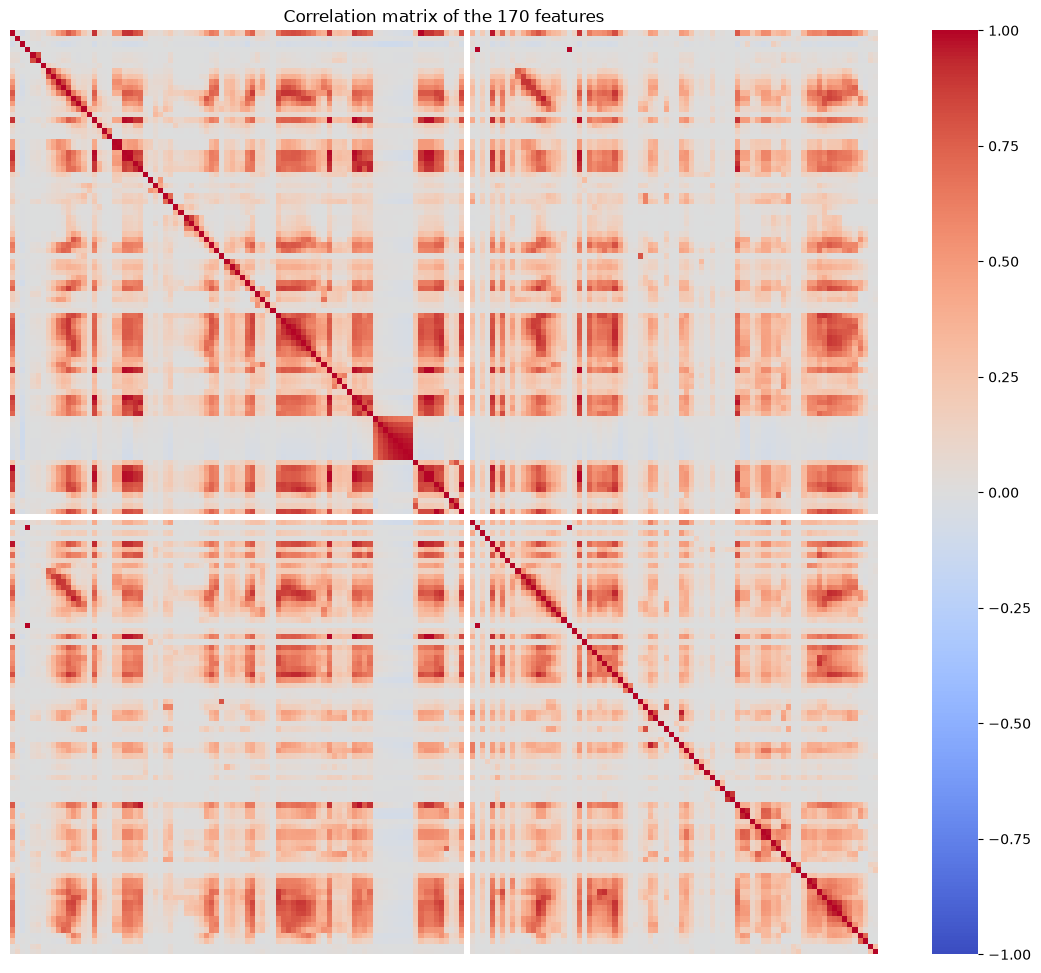

In [12]:
corr = train[features].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title('Correlation matrix of the 170 features')
plt.show()

The white row/column is cd_000, which is constant. Almost all correlations are positive, and many features are nearly redundant (130 pairs have |r| > 0.9, e.g. bu_000, bv_000 and cq_000 with r = 1.00). The r = 1.00 between cf_000, co_000 and ad_000 is caused by one outlier row (see part iv).

### iv. Scatter plots and box plots for the 13 features with highest CV

In [13]:
top_cv = list(cv.index[:13])
top_cv

['cf_000',
 'co_000',
 'ad_000',
 'cs_009',
 'dh_000',
 'dj_000',
 'ag_000',
 'as_000',
 'ay_009',
 'ak_000',
 'az_009',
 'ch_000',
 'au_000']

Most values are 0 and the rest span many orders of magnitude, so I plot log(1 + x).

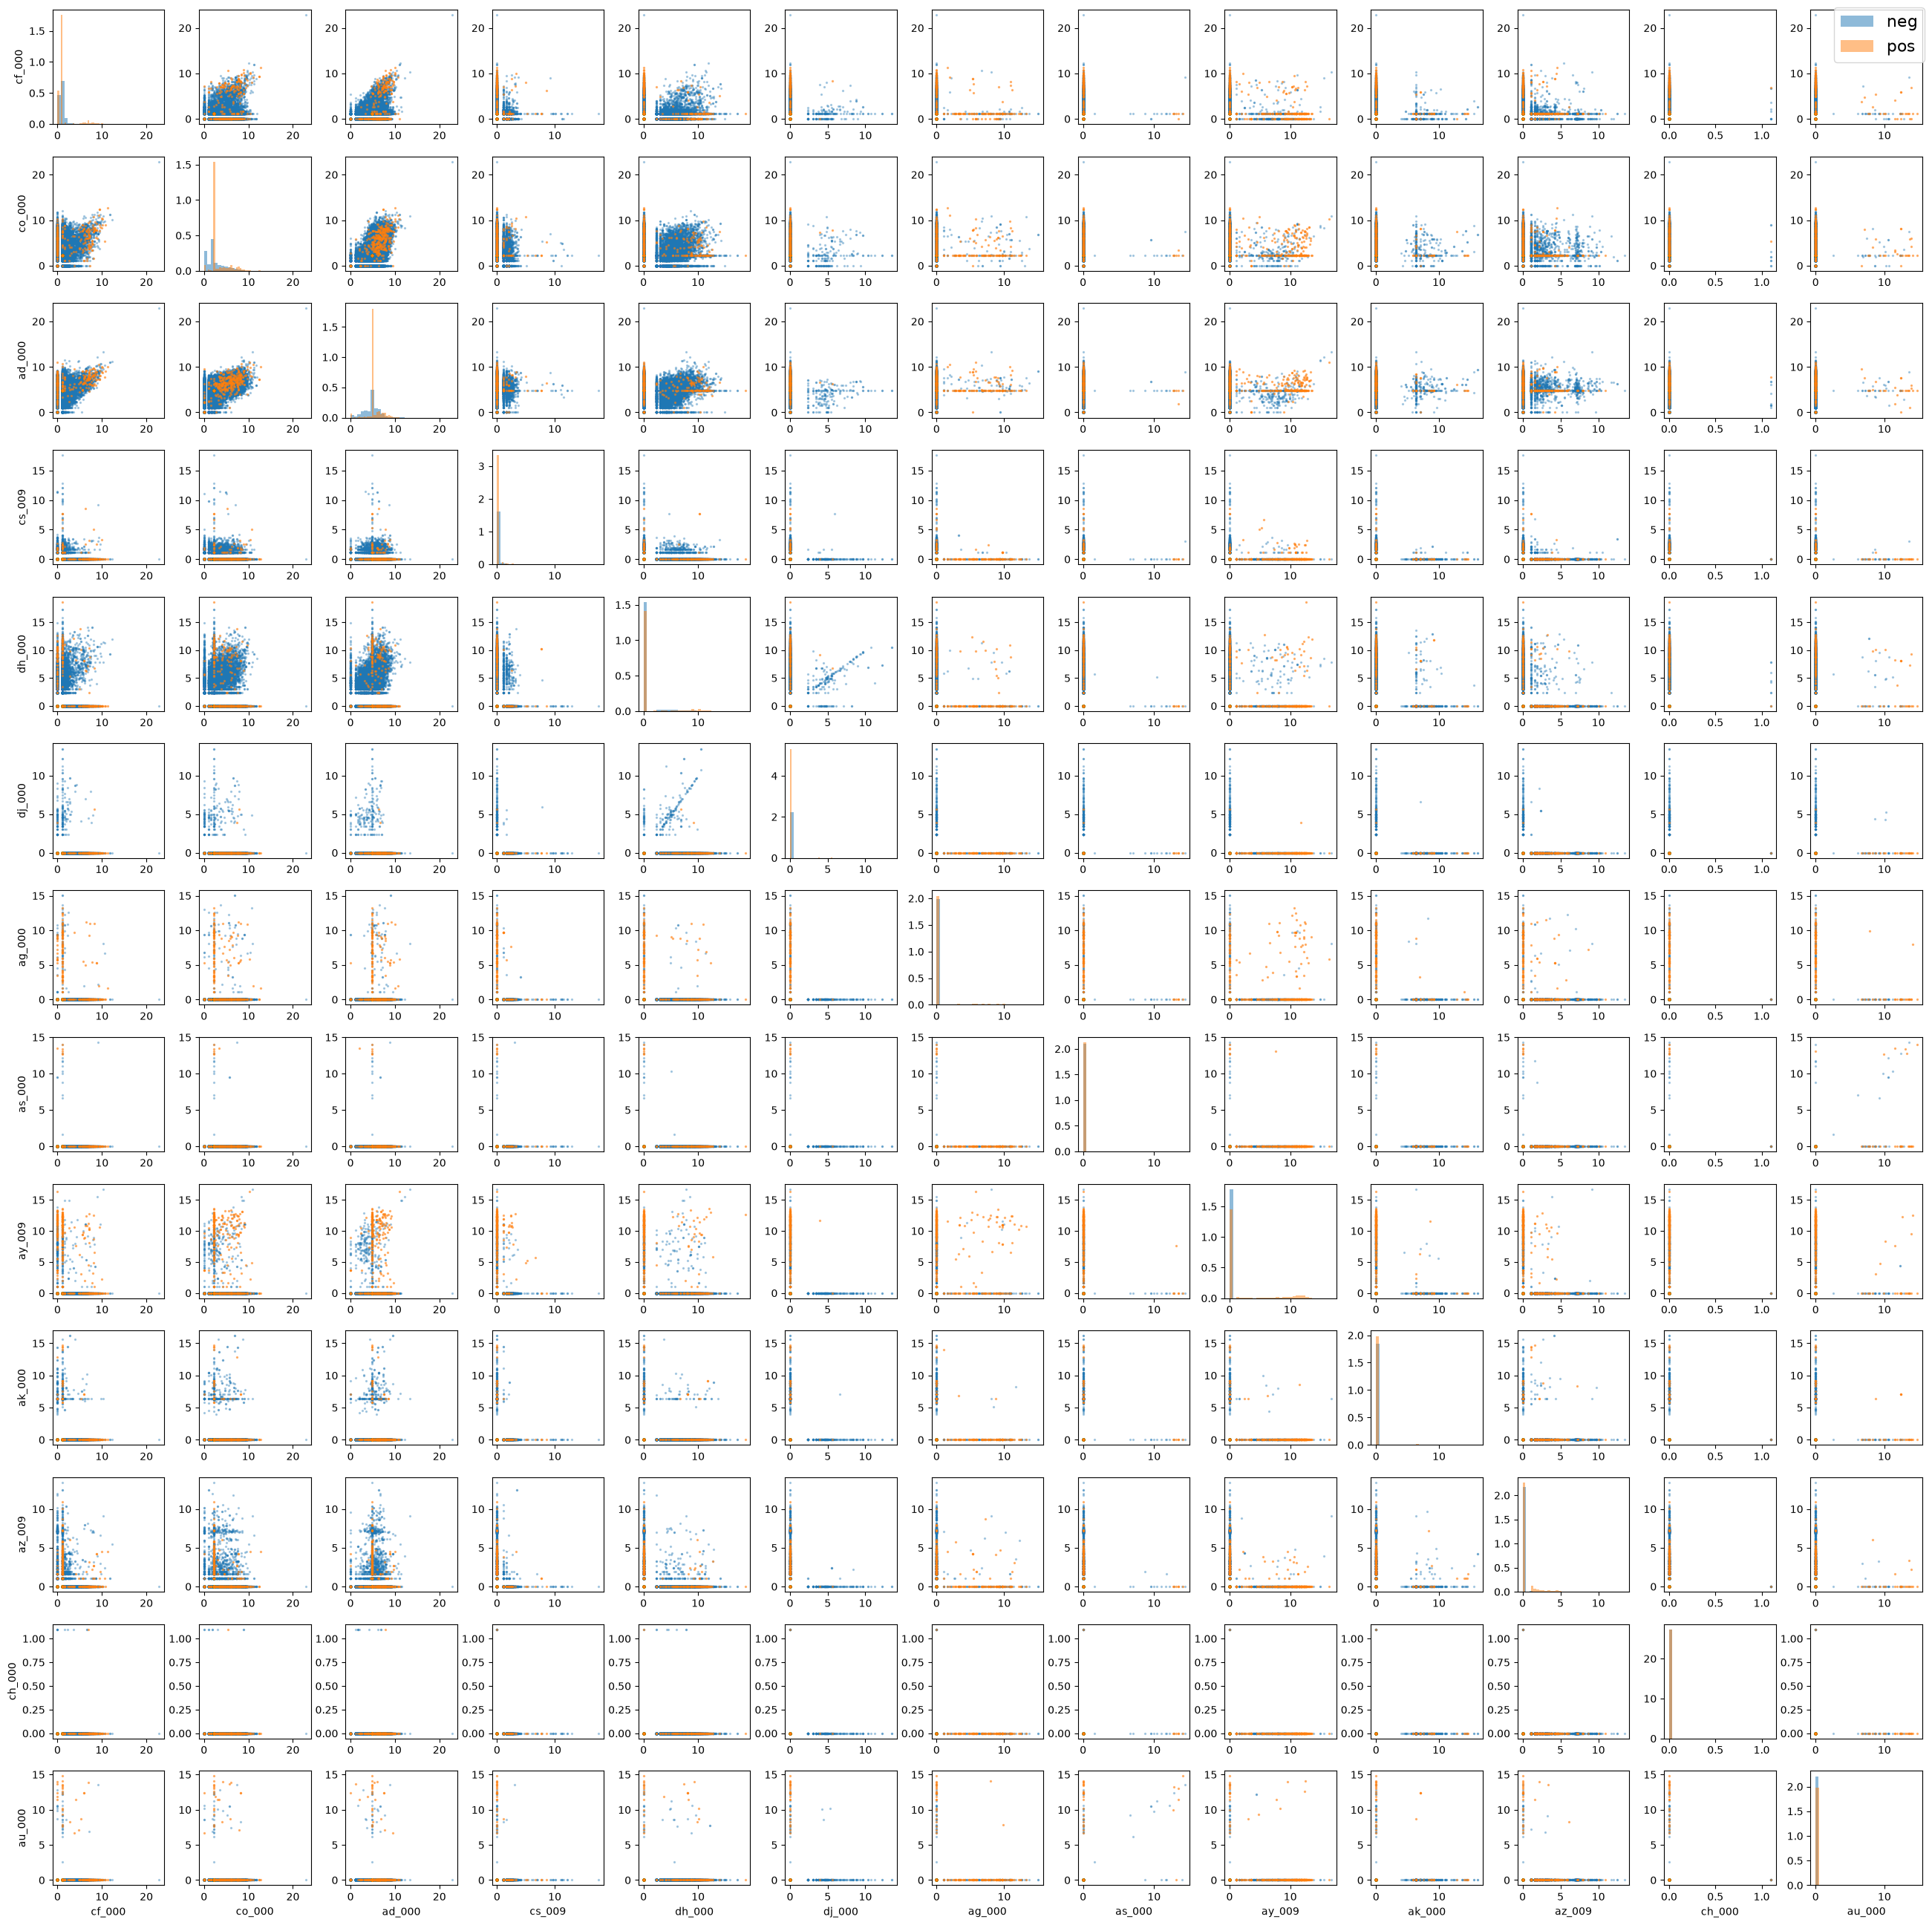

In [14]:
log_top = np.log1p(train[top_cv])
neg_log = log_top[train['class'] == 0]
pos_log = log_top[train['class'] == 1]

fig, axes = plt.subplots(13, 13, figsize=(26, 26))
for i in range(13):
    for j in range(13):
        ax = axes[i, j]
        if i == j:
            ax.hist(neg_log[top_cv[i]], bins=30, color='tab:blue', alpha=0.5, density=True)
            ax.hist(pos_log[top_cv[i]], bins=30, color='tab:orange', alpha=0.5, density=True)
        else:
            ax.scatter(neg_log[top_cv[j]], neg_log[top_cv[i]], s=2, color='tab:blue', alpha=0.3)
            ax.scatter(pos_log[top_cv[j]], pos_log[top_cv[i]], s=2, color='tab:orange', alpha=0.5)
        if i == 12:
            ax.set_xlabel(top_cv[j])
        if j == 0:
            ax.set_ylabel(top_cv[i])

fig.legend(['neg', 'pos'], loc='upper right', fontsize=16, markerscale=5)
plt.tight_layout()
plt.show()

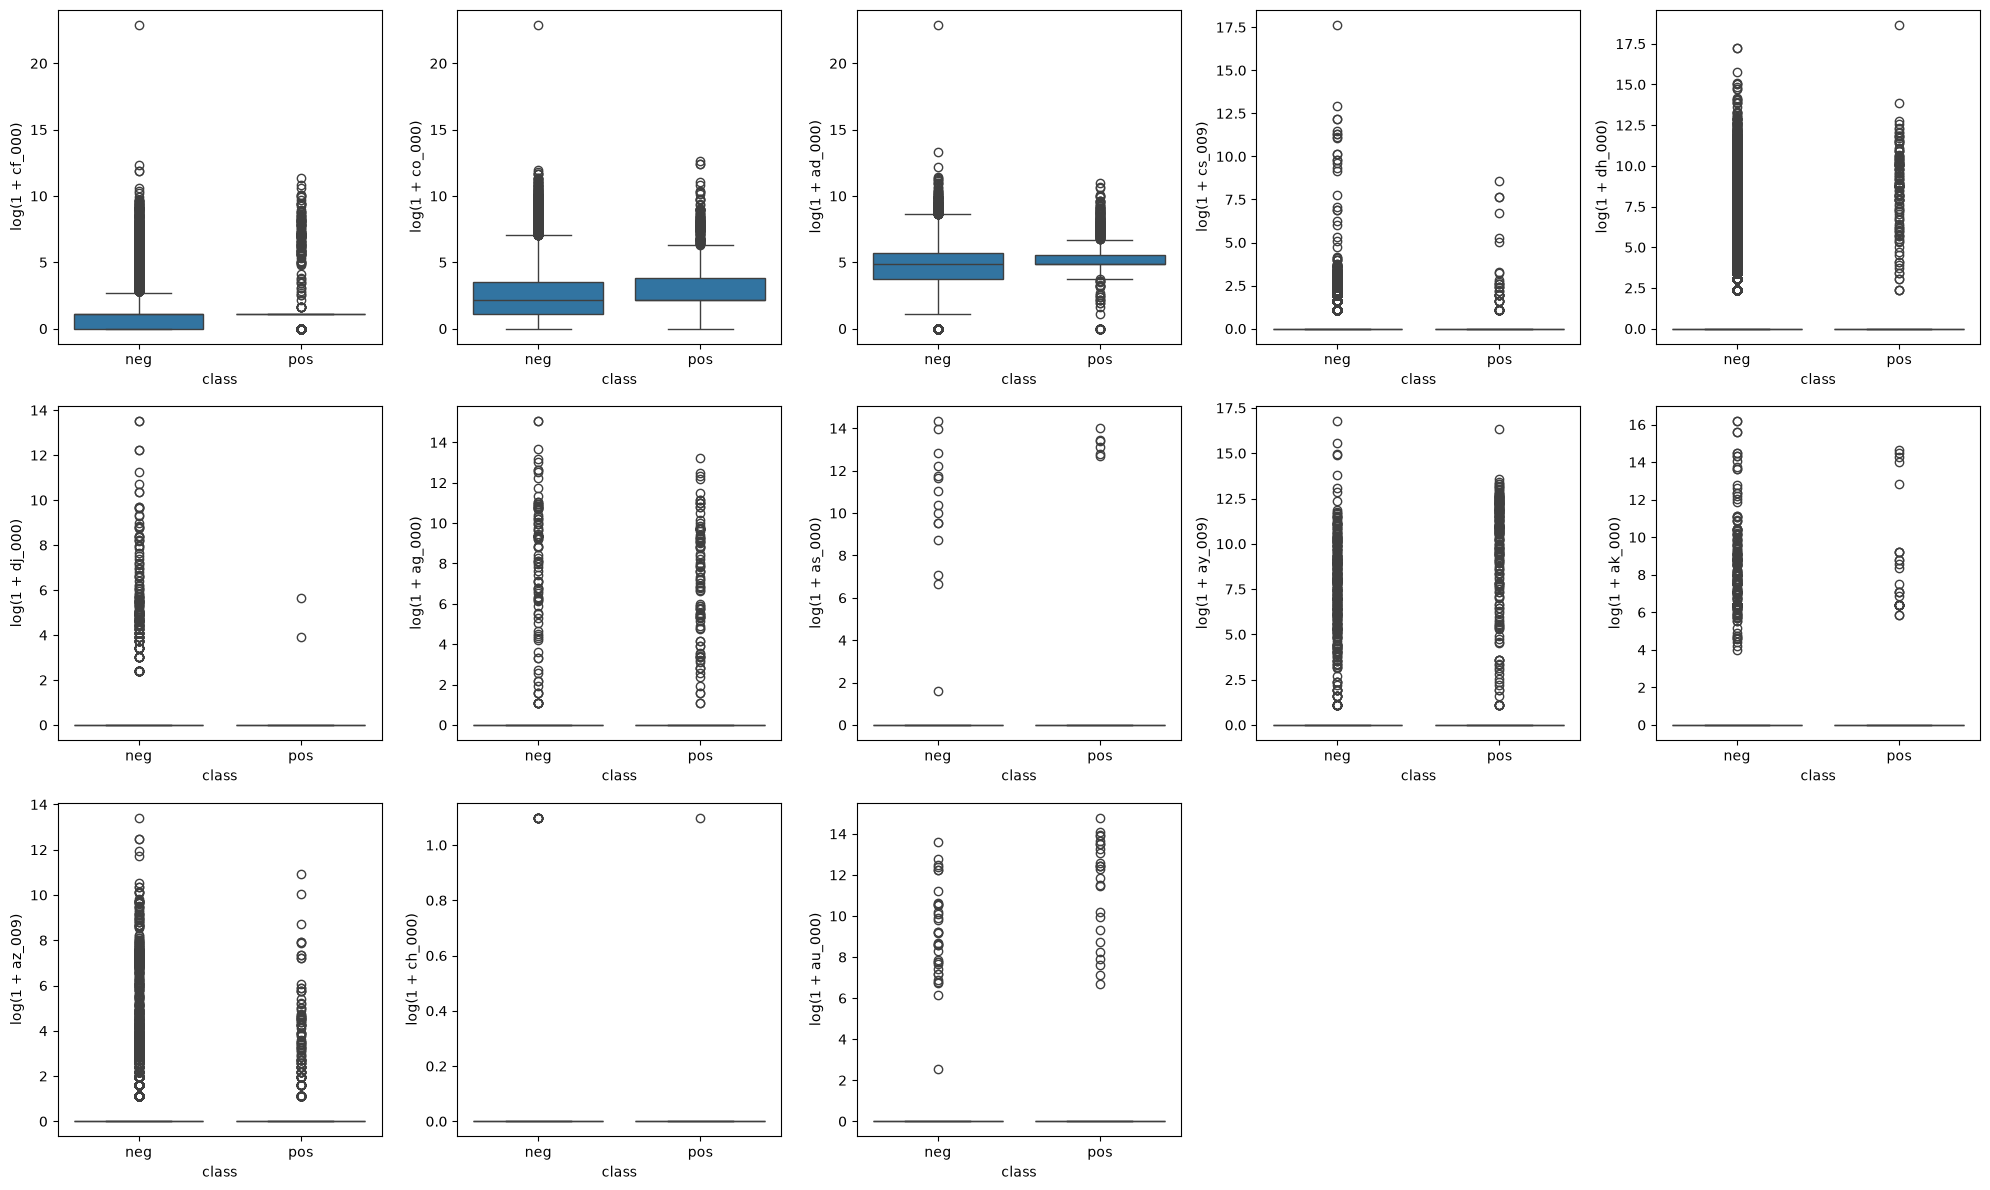

In [15]:
log_top['class'] = train['class']

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()
for i in range(13):
    sns.boxplot(data=log_top, x='class', y=top_cv[i], ax=axes[i])
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['neg', 'pos'])
    axes[i].set_ylabel('log(1 + ' + top_cv[i] + ')')
axes[13].axis('off')
axes[14].axis('off')
plt.tight_layout()
plt.show()

In [16]:
# Fraction of rows where each feature is not 0, for each class
nonzero = pd.DataFrame({
    'neg': (train.loc[train['class'] == 0, top_cv] > 0).mean(),
    'pos': (train.loc[train['class'] == 1, top_cv] > 0).mean(),
})
nonzero.round(3)

,neg,pos
cf_000,0.640,0.796
co_000,0.784,0.964
ad_000,0.966,0.973
cs_009,0.048,0.052
dh_000,0.116,0.119
dj_000,0.003,0.002
ag_000,0.002,0.097
as_000,0.000,0.006
ay_009,0.006,0.207
ak_000,0.006,0.031


In [17]:
# The top 3 CV features all get their maximum from the same row
print(train[top_cv[:3]].idxmax())
print(train.loc[train[top_cv[:3]].idxmax().iloc[0], top_cv[:3]])

cf_000    45977
co_000    45977
ad_000    45977
dtype: int64
cf_000    8.584298e+09
co_000    8.584298e+09
ad_000    8.584298e+09
Name: 45977, dtype: float64


**Can we draw conclusions about significance from the scatter plots?**

Not really, they only give hints. Some features look useful: ag_000, ay_009, az_009, ak_000, as_000 and au_000 are almost always 0 for negatives but often non-zero for positives, and co_000 and ad_000 are higher for positives. Others like cs_009, dh_000 and dj_000 look the same for both classes. But:

- High CV does not mean useful. The top 3 are only there because of one row with a value of about 8.6 billion, and most of the others are mostly zeros.
- The positives are hidden behind 59 times as many negatives.
- The plots show at most two features at a time, so they miss combinations and redundancy.
- A plot is not a statistical test.

### v. Positive and negative data

In [18]:
print('Training set')
print(train['class'].value_counts())
print()
print('Test set')
print(test['class'].value_counts())

Training set
class
0    59000
1     1000
Name: count, dtype: int64

Test set
class
0    15625
1      375
Name: count, dtype: int64


In [19]:
print('Negative to positive ratio in train:', train['class'].value_counts()[0] / train['class'].value_counts()[1])
print('Percent positive in train:', 100 * train['class'].mean())

Negative to positive ratio in train: 59.0
Percent positive in train: 1.6666666666666667


Yes, it is very imbalanced: 59 negatives for every positive (1.67% positive). Always predicting negative already gives 98.3% accuracy, so accuracy alone is not a good measure here.

## 1(c) Random forest without compensating for class imbalance

In [20]:
X_train = train[features]
y_train = train['class']
X_test = test[features]
y_test = test['class']

In [21]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.B

In [22]:
train_pred = rf.predict(X_train)
test_pred = rf.predict(X_test)

train_prob = rf.predict_proba(X_train)[:, 1]
test_prob = rf.predict_proba(X_test)[:, 1]

In [23]:
cm_train = confusion_matrix(y_train, train_pred)
print('Confusion matrix (train)')
pd.DataFrame(cm_train, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (train)


,pred neg,pred pos
true neg,59000,0
true pos,0,1000


In [24]:
cm_test = confusion_matrix(y_test, test_pred)
print('Confusion matrix (test)')
pd.DataFrame(cm_test, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (test)


,pred neg,pred pos
true neg,15606,19
true pos,101,274


In [25]:
train_error = (train_pred != y_train).mean()
test_error = (test_pred != y_test).mean()
train_auc = roc_auc_score(y_train, train_prob)
test_auc = roc_auc_score(y_test, test_prob)

print('Train misclassification:', round(train_error, 5))
print('Test misclassification:', round(test_error, 5))
print('Train AUC:', round(train_auc, 5))
print('Test AUC:', round(test_auc, 5))

Train misclassification: 0.0
Test misclassification: 0.0075
Train AUC: 1.0
Test AUC: 0.99442


In [26]:
# Precision, recall and F1 are for the positive class (APS failure)
pd.DataFrame({
    'accuracy': [accuracy_score(y_train, train_pred), accuracy_score(y_test, test_pred)],
    'precision': [precision_score(y_train, train_pred), precision_score(y_test, test_pred)],
    'recall': [recall_score(y_train, train_pred), recall_score(y_test, test_pred)],
    'F1': [f1_score(y_train, train_pred), f1_score(y_test, test_pred)],
    'AUC': [train_auc, test_auc],
}, index=['train', 'test']).round(4)

,accuracy,precision,recall,F1,AUC
train,1.0000,1.0000,1.0000,1.0000,1.0000
test,0.9925,0.9352,0.7307,0.8204,0.9944


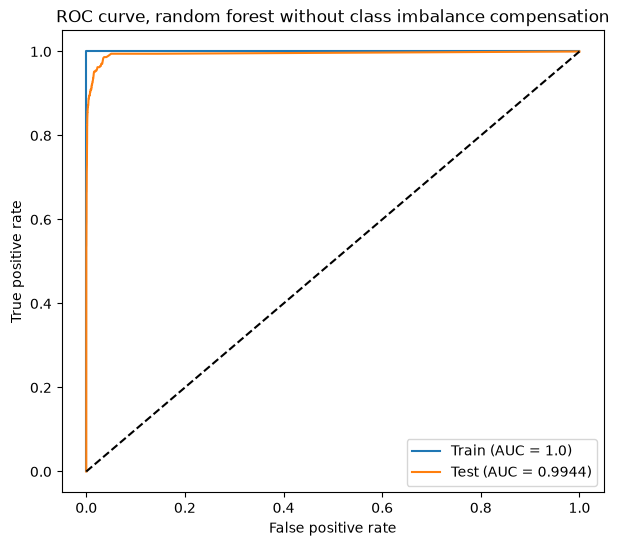

In [27]:
fpr_train, tpr_train, _ = roc_curve(y_train, train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr_train, tpr_train, label='Train (AUC = ' + str(round(train_auc, 4)) + ')')
plt.plot(fpr_test, tpr_test, label='Test (AUC = ' + str(round(test_auc, 4)) + ')')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve, random forest without class imbalance compensation')
plt.legend()
plt.show()

In [28]:
oob_error = 1 - rf.oob_score_
print('OOB error estimate:', round(oob_error, 5))
print('Test error:', round(test_error, 5))

OOB error estimate: 0.00582
Test error: 0.0075


In [29]:
# Share of positives in each set
print('Percent positive in train:', round(100 * y_train.mean(), 2))
print('Percent positive in test:', round(100 * y_test.mean(), 2))

Percent positive in train: 1.67
Percent positive in test: 2.34


The training fit is perfect because the trees are grown until the leaves are pure, so it says nothing about generalization.

The low test error hides that 101 of 375 failures are missed (recall 0.73), while only 19 negatives are false alarms. The forest favors the majority class. AUC is still high, so the ranking is good and the problem is mainly the 0.5 threshold.

The OOB error (0.58%) is close to the test error (0.75%). It is a bit lower mostly because the test set has more positives (2.34% vs 1.67%), and most errors are missed positives.

## 1(d) Random forest with class imbalance compensation

Ways to handle imbalance in random forests:

- Class weights: weight the rare class more in the split criterion (class_weight='balanced' or 'balanced_subsample').
- Balanced random forest: each tree is trained on the positives plus an equal-size random sample of negatives.
- Resampling the data first (oversampling, SMOTE).
- Lowering the decision threshold.

First, class weights:

In [30]:
rf_weighted = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1, random_state=0,
                                     class_weight='balanced_subsample')
rf_weighted.fit(X_train, y_train)

weighted_test_pred = rf_weighted.predict(X_test)
print('Confusion matrix (test)')
pd.DataFrame(confusion_matrix(y_test, weighted_test_pred), index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (test)


,pred neg,pred pos
true neg,15606,19
true pos,157,218


Class weights do not help (157 missed instead of 101): with pure leaves, each leaf predicts the same class regardless of the weights. So I use a balanced random forest and repeat 1(c).

In [31]:
brf = BalancedRandomForestClassifier(n_estimators=300, sampling_strategy='auto', replacement=False,
                                     bootstrap=True, oob_score=True, n_jobs=-1, random_state=0)
brf.fit(X_train, y_train)

D:\USC\ML\.venv\Lib\site-packages\imblearn\ensemble\_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,n_estimators,300
,bootstrap,True
,oob_score,True
,sampling_strategy,'auto'
,replacement,False
,n_jobs,-1
,random_state,0
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1


In [32]:
brf_train_pred = brf.predict(X_train)
brf_test_pred = brf.predict(X_test)

brf_train_prob = brf.predict_proba(X_train)[:, 1]
brf_test_prob = brf.predict_proba(X_test)[:, 1]

In [33]:
brf_cm_train = confusion_matrix(y_train, brf_train_pred)
print('Confusion matrix (train)')
pd.DataFrame(brf_cm_train, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (train)


,pred neg,pred pos
true neg,55810,3190
true pos,0,1000


In [34]:
brf_cm_test = confusion_matrix(y_test, brf_test_pred)
print('Confusion matrix (test)')
pd.DataFrame(brf_cm_test, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (test)


,pred neg,pred pos
true neg,14829,796
true pos,6,369


In [35]:
brf_train_error = (brf_train_pred != y_train).mean()
brf_test_error = (brf_test_pred != y_test).mean()
brf_train_auc = roc_auc_score(y_train, brf_train_prob)
brf_test_auc = roc_auc_score(y_test, brf_test_prob)

print('Train misclassification:', round(brf_train_error, 5))
print('Test misclassification:', round(brf_test_error, 5))
print('Train AUC:', round(brf_train_auc, 5))
print('Test AUC:', round(brf_test_auc, 5))

Train misclassification: 0.05317
Test misclassification: 0.05012
Train AUC: 0.99759
Test AUC: 0.99234


In [36]:
# Precision, recall and F1 are for the positive class (APS failure)
pd.DataFrame({
    'accuracy': [accuracy_score(y_train, brf_train_pred), accuracy_score(y_test, brf_test_pred)],
    'precision': [precision_score(y_train, brf_train_pred), precision_score(y_test, brf_test_pred)],
    'recall': [recall_score(y_train, brf_train_pred), recall_score(y_test, brf_test_pred)],
    'F1': [f1_score(y_train, brf_train_pred), f1_score(y_test, brf_test_pred)],
    'AUC': [brf_train_auc, brf_test_auc],
}, index=['train', 'test']).round(4)

,accuracy,precision,recall,F1,AUC
train,0.9468,0.2387,1.000,0.3854,0.9976
test,0.9499,0.3167,0.984,0.4792,0.9923


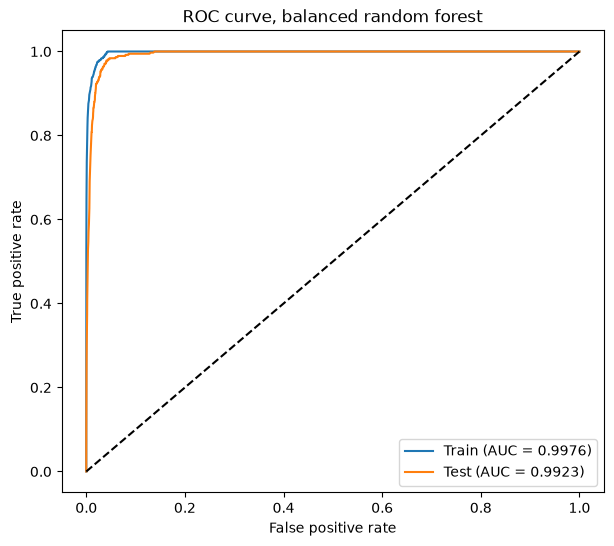

In [37]:
brf_fpr_train, brf_tpr_train, _ = roc_curve(y_train, brf_train_prob)
brf_fpr_test, brf_tpr_test, _ = roc_curve(y_test, brf_test_prob)

plt.figure(figsize=(7, 6))
plt.plot(brf_fpr_train, brf_tpr_train, label='Train (AUC = ' + str(round(brf_train_auc, 4)) + ')')
plt.plot(brf_fpr_test, brf_tpr_test, label='Test (AUC = ' + str(round(brf_test_auc, 4)) + ')')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve, balanced random forest')
plt.legend()
plt.show()

In [38]:
brf_oob_error = 1 - brf.oob_score_
print('OOB error estimate:', round(brf_oob_error, 5))
print('Test error:', round(brf_test_error, 5))

OOB error estimate: 0.05082
Test error: 0.05012


In [39]:
# The dataset description gives a cost: 10 for a false alarm and 500 for a missed failure
cost_1c = 10 * cm_test[0, 1] + 500 * cm_test[1, 0]
cost_1d = 10 * brf_cm_test[0, 1] + 500 * brf_cm_test[1, 0]

print('Positives caught (test), 1(c):', cm_test[1, 1], 'of', cm_test[1].sum())
print('Positives caught (test), 1(d):', brf_cm_test[1, 1], 'of', brf_cm_test[1].sum())
print('Total cost (test), 1(c):', cost_1c)
print('Total cost (test), 1(d):', cost_1d)

Positives caught (test), 1(c): 274 of 375
Positives caught (test), 1(d): 369 of 375
Total cost (test), 1(c): 50690
Total cost (test), 1(d): 10960


**Comparison with 1(c)**

Missed failures drop from 101 to 6 (recall 0.73 to 0.98), but false alarms go up from 19 to 796 (precision 0.94 to 0.32). So error rate and F1 get worse, while AUC barely changes: compensation does not improve the ranking, it moves the decision boundary.

Which is better depends on the costs. A missed failure costs 50 times more than a false alarm, so with the dataset's costs the balanced forest is much better (10,960 vs 50,690). F1 treats both errors equally, which is why it prefers 1(c).

The training fit is no longer perfect since each tree only sees about 1,000 negatives. OOB (5.08%) is again very close to the test error (5.01%).

## 1(e) XGBoost with L1-penalized logistic regression

XGBoost with the logistic loss (binary:logistic) and the L1 penalty reg_alpha on the leaf weights. Alpha is chosen by 5-fold stratified CV, comparing by AUC since accuracy is not informative here.

In [40]:
alphas = [0, 0.01, 0.1, 1, 10, 100, 1000]

xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, tree_method='hist',
                    n_jobs=-1, random_state=0)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

grid = GridSearchCV(xgb, {'reg_alpha': alphas}, scoring={'auc': 'roc_auc', 'accuracy': 'accuracy'},
                    refit='auc', cv=folds)
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'reg_alpha': [0, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'auc': 'roc_auc'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, defa

In [41]:
cv_results = pd.DataFrame(grid.cv_results_)
cv_results['cv_error'] = 1 - cv_results['mean_test_accuracy']
cv_results[['param_reg_alpha', 'mean_test_auc', 'std_test_auc', 'cv_error']]

,param_reg_alpha,mean_test_auc,std_test_auc,cv_error
0,0.00,0.989692,0.004309,0.005450
1,0.01,0.989982,0.004070,0.005433
2,0.10,0.990171,0.004111,0.005550
3,1.00,0.989619,0.004521,0.005667
4,10.00,0.988635,0.005429,0.006817
5,100.00,0.982621,0.006179,0.011467
6,1000.00,0.500000,0.000000,0.016667


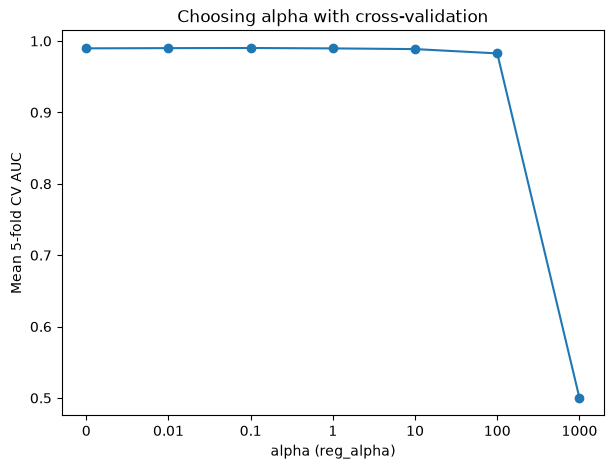

In [42]:
plt.figure(figsize=(7, 5))
plt.plot([str(a) for a in alphas], cv_results['mean_test_auc'], marker='o')
plt.xlabel('alpha (reg_alpha)')
plt.ylabel('Mean 5-fold CV AUC')
plt.title('Choosing alpha with cross-validation')
plt.show()

In [43]:
print('Best alpha:', grid.best_params_['reg_alpha'])
xgb_best = grid.best_estimator_

Best alpha: 0.1


The CV AUC is almost flat for alpha from 0 to 1, and alpha = 0.1 is best by a small margin. At alpha = 1000 all leaf weights are 0 and the model predicts all negative (AUC = 0.5).

In [44]:
xgb_train_pred = xgb_best.predict(X_train)
xgb_test_pred = xgb_best.predict(X_test)

xgb_train_prob = xgb_best.predict_proba(X_train)[:, 1]
xgb_test_prob = xgb_best.predict_proba(X_test)[:, 1]

In [45]:
xgb_cm_train = confusion_matrix(y_train, xgb_train_pred)
print('Confusion matrix (train)')
pd.DataFrame(xgb_cm_train, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (train)


,pred neg,pred pos
true neg,59000,0
true pos,2,998


In [46]:
xgb_cm_test = confusion_matrix(y_test, xgb_test_pred)
print('Confusion matrix (test)')
pd.DataFrame(xgb_cm_test, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (test)


,pred neg,pred pos
true neg,15609,16
true pos,86,289


In [47]:
xgb_train_error = (xgb_train_pred != y_train).mean()
xgb_test_error = (xgb_test_pred != y_test).mean()
xgb_train_auc = roc_auc_score(y_train, xgb_train_prob)
xgb_test_auc = roc_auc_score(y_test, xgb_test_prob)
xgb_cv_error = cv_results.loc[grid.best_index_, 'cv_error']

print('Train misclassification:', round(xgb_train_error, 5))
print('5-fold CV error estimate:', round(xgb_cv_error, 5))
print('Test misclassification:', round(xgb_test_error, 5))
print('Train AUC:', round(xgb_train_auc, 5))
print('Test AUC:', round(xgb_test_auc, 5))

Train misclassification: 3e-05
5-fold CV error estimate: 0.00555
Test misclassification: 0.00638
Train AUC: 0.99998
Test AUC: 0.99517


In [48]:
# Precision, recall and F1 are for the positive class (APS failure)
pd.DataFrame({
    'accuracy': [accuracy_score(y_train, xgb_train_pred), accuracy_score(y_test, xgb_test_pred)],
    'precision': [precision_score(y_train, xgb_train_pred), precision_score(y_test, xgb_test_pred)],
    'recall': [recall_score(y_train, xgb_train_pred), recall_score(y_test, xgb_test_pred)],
    'F1': [f1_score(y_train, xgb_train_pred), f1_score(y_test, xgb_test_pred)],
    'AUC': [xgb_train_auc, xgb_test_auc],
}, index=['train', 'test']).round(4)

,accuracy,precision,recall,F1,AUC
train,1.0000,1.0000,0.9980,0.999,1.0000
test,0.9936,0.9475,0.7707,0.850,0.9952


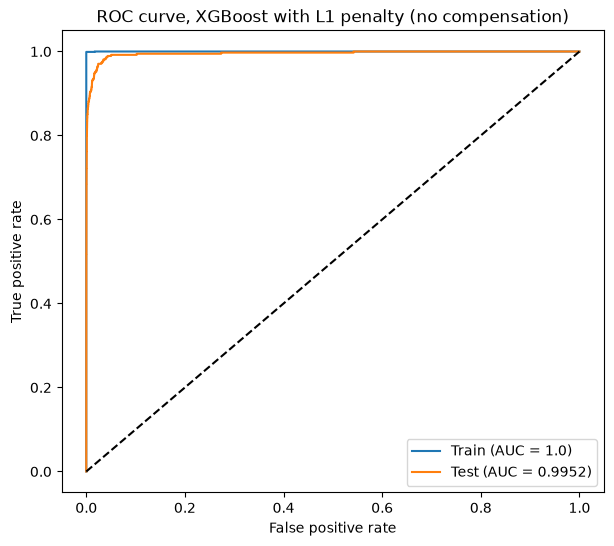

In [49]:
xgb_fpr_train, xgb_tpr_train, _ = roc_curve(y_train, xgb_train_prob)
xgb_fpr_test, xgb_tpr_test, _ = roc_curve(y_test, xgb_test_prob)

plt.figure(figsize=(7, 6))
plt.plot(xgb_fpr_train, xgb_tpr_train, label='Train (AUC = ' + str(round(xgb_train_auc, 4)) + ')')
plt.plot(xgb_fpr_test, xgb_tpr_test, label='Test (AUC = ' + str(round(xgb_test_auc, 4)) + ')')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve, XGBoost with L1 penalty (no compensation)')
plt.legend()
plt.show()

In [50]:
xgb_cost = 10 * xgb_cm_test[0, 1] + 500 * xgb_cm_test[1, 0]
print('Positives caught (test):', xgb_cm_test[1, 1], 'of', xgb_cm_test[1].sum())
print('Total cost (test):', xgb_cost)

Positives caught (test): 289 of 375
Total cost (test): 43160


The CV error (0.555%) is a good estimate of the test error (0.638%). It is slightly lower because the same folds chose alpha and because the test set has more positives.

Compared to the random forest in 1(c), XGBoost is a bit better on every test metric (recall 0.77 vs 0.73, F1 0.85 vs 0.82, cost 43,160 vs 50,690), but without compensation it still misses 86 failures.

## 1(f) SMOTE + XGBoost

SMOTE creates synthetic positives by interpolating between a positive point and one of its 5 nearest positive neighbors, until both classes have the same size.

**Right vs wrong CV.** Applying SMOTE before CV puts synthetic points in the validation folds that were made from training-fold points, so CV is far too optimistic. The right way is to apply SMOTE only to the training part of each fold. An imblearn Pipeline does this, since SMOTE runs during fit but not predict.

In [51]:
smote_pipe = Pipeline([
    ('smote', SMOTE(random_state=0)),
    ('xgb', XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, tree_method='hist',
                          n_jobs=-1, random_state=0)),
])

cv_scoring = {'auc': 'roc_auc', 'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}

smote_grid = GridSearchCV(smote_pipe, {'xgb__reg_alpha': alphas}, scoring=cv_scoring, refit='auc', cv=folds)
smote_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'xgb__reg_alpha': [0, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'auc': 'roc_auc', 'f1': 'f1', 'precision': 'precision', ...}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed f

In [52]:
smote_cv = pd.DataFrame(smote_grid.cv_results_)
smote_cv['cv_error'] = 1 - smote_cv['mean_test_accuracy']
smote_cv[['param_xgb__reg_alpha', 'mean_test_auc', 'cv_error', 'mean_test_precision', 'mean_test_recall', 'mean_test_f1']]

,param_xgb__reg_alpha,mean_test_auc,cv_error,mean_test_precision,mean_test_recall,mean_test_f1
0,0.00,0.989556,0.006733,0.779572,0.832,0.804681
1,0.01,0.989161,0.006750,0.776696,0.837,0.805252
2,0.10,0.988918,0.006800,0.776338,0.835,0.803780
3,1.00,0.989018,0.006783,0.777226,0.834,0.803976
4,10.00,0.988995,0.007817,0.729486,0.846,0.782997
5,100.00,0.985055,0.018250,0.476293,0.888,0.619539
6,1000.00,0.981690,0.040083,0.285525,0.932,0.437028


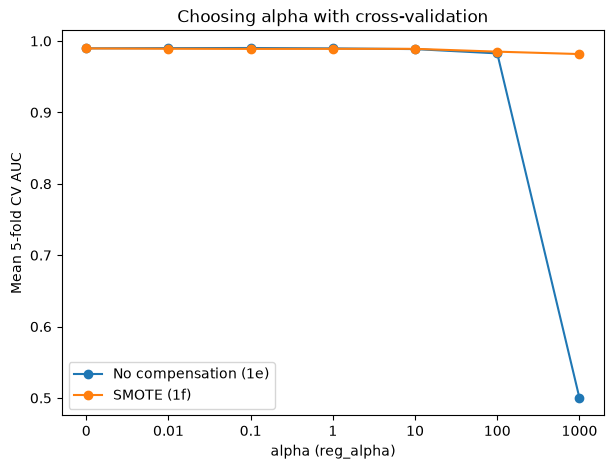

In [53]:
plt.figure(figsize=(7, 5))
plt.plot([str(a) for a in alphas], cv_results['mean_test_auc'], marker='o', label='No compensation (1e)')
plt.plot([str(a) for a in alphas], smote_cv['mean_test_auc'], marker='o', label='SMOTE (1f)')
plt.xlabel('alpha (reg_alpha)')
plt.ylabel('Mean 5-fold CV AUC')
plt.title('Choosing alpha with cross-validation')
plt.legend()
plt.show()

In [54]:
print('Best alpha:', smote_grid.best_params_['xgb__reg_alpha'])
smote_best = smote_grid.best_estimator_

Best alpha: 0


CV picks alpha = 0, but AUC is within 0.001 for alpha from 0 to 10. With balanced classes a large alpha no longer predicts all negatives; it flags more trucks instead (higher recall, lower precision).

The final pipeline applies SMOTE to the full training set. Training metrics are on the original training data.

In [55]:
smote_train_pred = smote_best.predict(X_train)
smote_test_pred = smote_best.predict(X_test)

smote_train_prob = smote_best.predict_proba(X_train)[:, 1]
smote_test_prob = smote_best.predict_proba(X_test)[:, 1]

In [56]:
smote_cm_train = confusion_matrix(y_train, smote_train_pred)
print('Confusion matrix (train)')
pd.DataFrame(smote_cm_train, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (train)


,pred neg,pred pos
true neg,58997,3
true pos,6,994


In [57]:
smote_cm_test = confusion_matrix(y_test, smote_test_pred)
print('Confusion matrix (test)')
pd.DataFrame(smote_cm_test, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])

Confusion matrix (test)


,pred neg,pred pos
true neg,15546,79
true pos,55,320


In [58]:
smote_train_error = (smote_train_pred != y_train).mean()
smote_test_error = (smote_test_pred != y_test).mean()
smote_train_auc = roc_auc_score(y_train, smote_train_prob)
smote_test_auc = roc_auc_score(y_test, smote_test_prob)
smote_cv_error = smote_cv.loc[smote_grid.best_index_, 'cv_error']

print('Train misclassification:', round(smote_train_error, 5))
print('5-fold CV error estimate:', round(smote_cv_error, 5))
print('Test misclassification:', round(smote_test_error, 5))
print('Train AUC:', round(smote_train_auc, 5))
print('Test AUC:', round(smote_test_auc, 5))

Train misclassification: 0.00015
5-fold CV error estimate: 0.00673
Test misclassification: 0.00838
Train AUC: 0.99996
Test AUC: 0.99417


In [59]:
# Precision, recall and F1 are for the positive class (APS failure)
pd.DataFrame({
    'accuracy': [accuracy_score(y_train, smote_train_pred), accuracy_score(y_test, smote_test_pred)],
    'precision': [precision_score(y_train, smote_train_pred), precision_score(y_test, smote_test_pred)],
    'recall': [recall_score(y_train, smote_train_pred), recall_score(y_test, smote_test_pred)],
    'F1': [f1_score(y_train, smote_train_pred), f1_score(y_test, smote_test_pred)],
    'AUC': [smote_train_auc, smote_test_auc],
}, index=['train', 'test']).round(4)

,accuracy,precision,recall,F1,AUC
train,0.9998,0.997,0.9940,0.9955,1.0000
test,0.9916,0.802,0.8533,0.8269,0.9942


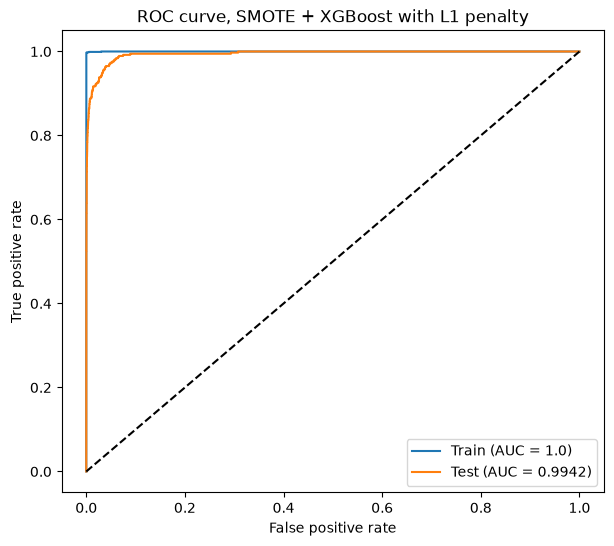

In [60]:
smote_fpr_train, smote_tpr_train, _ = roc_curve(y_train, smote_train_prob)
smote_fpr_test, smote_tpr_test, _ = roc_curve(y_test, smote_test_prob)

plt.figure(figsize=(7, 6))
plt.plot(smote_fpr_train, smote_tpr_train, label='Train (AUC = ' + str(round(smote_train_auc, 4)) + ')')
plt.plot(smote_fpr_test, smote_tpr_test, label='Test (AUC = ' + str(round(smote_test_auc, 4)) + ')')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve, SMOTE + XGBoost with L1 penalty')
plt.legend()
plt.show()

In [61]:
smote_cost = 10 * smote_cm_test[0, 1] + 500 * smote_cm_test[1, 0]
print('Positives caught (test):', smote_cm_test[1, 1], 'of', smote_cm_test[1].sum())
print('Total cost (test):', smote_cost)

Positives caught (test): 320 of 375
Total cost (test): 28290


**The wrong way, for comparison:** SMOTE on the whole training set, then CV.

In [62]:
X_smote, y_smote = SMOTE(random_state=0).fit_resample(X_train, y_train)
print('Size after SMOTE:', X_smote.shape)
print(y_smote.value_counts())

Size after SMOTE: (118000, 170)
class
0    59000
1    59000
Name: count, dtype: int64


In [63]:
wrong_xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, tree_method='hist',
                          n_jobs=-1, random_state=0, reg_alpha=smote_grid.best_params_['xgb__reg_alpha'])
wrong_cv = cross_validate(wrong_xgb, X_smote, y_smote, cv=folds, scoring=cv_scoring)

pd.DataFrame({
    'wrong way (SMOTE before CV)': [wrong_cv['test_' + m].mean() for m in cv_scoring],
    'right way (SMOTE inside CV)': [smote_cv.loc[smote_grid.best_index_, 'mean_test_' + m] for m in cv_scoring],
    'test set': [smote_test_auc, accuracy_score(y_test, smote_test_pred), precision_score(y_test, smote_test_pred),
                 recall_score(y_test, smote_test_pred), f1_score(y_test, smote_test_pred)],
}, index=list(cv_scoring)).round(4)

,wrong way (SMOTE before CV),right way (SMOTE inside CV),test set
auc,0.9999,0.9896,0.9942
accuracy,0.9973,0.9933,0.9916
precision,0.9955,0.7796,0.8020
recall,0.9992,0.8320,0.8533
f1,0.9974,0.8047,0.8269


The wrong way gives a CV F1 of 0.997, far above the test F1 of 0.83. The right way (0.80) is close to the test set. The right-way CV error (0.67%) is slightly below the test error (0.84%) for the same reasons as in 1(e).

In [64]:
pd.DataFrame({
    'no compensation (1e)': [accuracy_score(y_test, xgb_test_pred), precision_score(y_test, xgb_test_pred),
                             recall_score(y_test, xgb_test_pred), f1_score(y_test, xgb_test_pred), xgb_test_auc,
                             xgb_cm_test[1, 0], xgb_cm_test[0, 1], xgb_cost],
    'SMOTE (1f)': [accuracy_score(y_test, smote_test_pred), precision_score(y_test, smote_test_pred),
                   recall_score(y_test, smote_test_pred), f1_score(y_test, smote_test_pred), smote_test_auc,
                   smote_cm_test[1, 0], smote_cm_test[0, 1], smote_cost],
}, index=['accuracy', 'precision', 'recall', 'F1', 'AUC', 'missed failures', 'false alarms', 'cost']).round(4)

,no compensation (1e),SMOTE (1f)
accuracy,0.9936,0.9916
precision,0.9475,0.8020
recall,0.7707,0.8533
F1,0.8500,0.8269
AUC,0.9952,0.9942
missed failures,86.0000,55.0000
false alarms,16.0000,79.0000
cost,43160.0000,28290.0000


**Comparison of the uncompensated case and the SMOTE case**

SMOTE catches 320 failures instead of 289 (recall 0.77 to 0.85), at the cost of more false alarms (precision 0.95 to 0.80). Accuracy, F1 and AUC barely change; as with the random forests, the decision boundary moves but the ranking stays the same. With the dataset's costs, SMOTE is better (28,290 vs 43,160). It is a milder correction than the balanced random forest, which still has the lowest cost of all models (10,960).

**Note:** I used Claude to help write the markdown text and make the graphs for the ISLR questions (2 to 5).

## 2. ISLR 6.6.3

This is the lasso with budget $s$. At $s = 0$ all $\beta_j = 0$; as $s$ grows the model gets more flexible, until it reaches least squares.

**(a) iv. Steadily decrease.** A larger $s$ allows every earlier solution plus more, so training RSS can only go down.

**(b) ii. U shape.** Test RSS first falls as bias drops, then rises once the model starts fitting noise.

**(c) iii. Steadily increase.** More flexibility means more variance.

**(d) iv. Steadily decrease.** Less shrinkage means less bias.

**(e) v. Remain constant.** Irreducible error comes from the noise, not the model.

## 3. ISLR 6.6.5

Here $x_{11} = x_{12}$, $x_{21} = x_{22}$ and $\hat\beta_0 = 0$.

**(a)** Ridge:
$$\min_{\beta_1, \beta_2} \; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2)$$

**(b)** Since the features are equal, the RSS is $(y_1 - (\beta_1 + \beta_2) x_{11})^2 + (y_2 - (\beta_1 + \beta_2) x_{21})^2$, which is symmetric in $\beta_1$ and $\beta_2$. So the two partial derivatives have the same RSS term and differ only in the penalty term ($2\lambda\beta_1$ vs $2\lambda\beta_2$). Subtracting them gives $2\lambda(\beta_1 - \beta_2) = 0$, so $\hat\beta_1 = \hat\beta_2$.

**(c)** Lasso:
$$\min_{\beta_1, \beta_2} \; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|)$$

**(d)** The RSS depends only on $c = \beta_1 + \beta_2$, and $|\beta_1| + |\beta_2| \ge |c|$ with equality when $\beta_1$ and $\beta_2$ have the same sign. So if $\hat c$ is the best sum, every split with the same sign is a solution:
$$\hat\beta_1 + \hat\beta_2 = \hat c, \quad \hat\beta_1, \hat\beta_2 \ge 0 \quad (\text{if } \hat c > 0, \text{ or both} \le 0 \text{ if } \hat c < 0)$$
This is a whole line segment: the RSS contours are parallel to an edge of the lasso diamond, so they touch it along that edge.

## 4. ISLR 8.4.5

In [65]:
probs = [0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75]

red_votes = 0
for p in probs:
    if p > 0.5:
        red_votes = red_votes + 1

print('Trees voting Red:', red_votes)
print('Trees voting Green:', len(probs) - red_votes)
print('Average probability of Red:', np.mean(probs))

Trees voting Red: 6
Trees voting Green: 4
Average probability of Red: 0.45


**Majority vote:** 6 trees vote Red and 4 vote Green, so **Red**.

**Average probability:** 0.45 < 0.5, so **Green**.

## 5. ISLR 9.7.3

**(a)** The 7 observations:

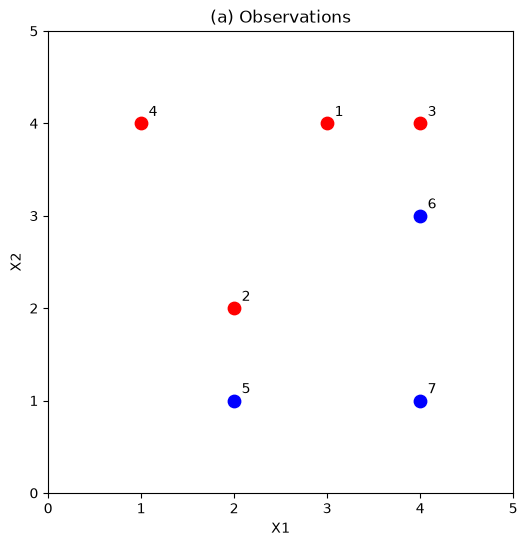

In [66]:
obs_x1 = [3, 2, 4, 1, 2, 4, 4]
obs_x2 = [4, 2, 4, 4, 1, 3, 1]
obs_y = ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue']

plt.figure(figsize=(6, 6))
for i in range(7):
    plt.scatter(obs_x1[i], obs_x2[i], color=obs_y[i].lower(), s=80)
    plt.text(obs_x1[i] + 0.08, obs_x2[i] + 0.08, str(i + 1))
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('(a) Observations')
plt.show()

**(b)** The closest red points (2 and 3) lie on $X_2 = X_1$ and the closest blue points (5 and 6) lie on $X_2 = X_1 - 1$. The hyperplane is halfway between them:
$$0.5 - X_1 + X_2 = 0$$
Checked below with a hard-margin SVM (linear kernel, very large C).

In [67]:
X_toy = np.array([obs_x1, obs_x2]).T
y_toy = np.array([1, 1, 1, 1, 0, 0, 0])  # 1 = Red, 0 = Blue

svm = SVC(kernel='linear', C=1e6)
svm.fit(X_toy, y_toy)

w = svm.coef_[0]
b = svm.intercept_[0]
print('Fitted hyperplane:', round(b, 4), '+', round(w[0], 4), '* X1 +', round(w[1], 4), '* X2 = 0')
print('Divided by', round(w[1], 4), ':', round(b / w[1], 4), '+', round(w[0] / w[1], 4), '* X1 +', 1.0, '* X2 = 0')
print('Support vectors (observation numbers):', sorted((svm.support_ + 1).tolist()))
print('Margin:', round(1 / np.linalg.norm(w), 4))

Fitted hyperplane: 0.9997 + -1.9994 * X1 + 1.9994 * X2 = 0
Divided by 1.9994 : 0.5 + -1.0 * X1 + 1.0 * X2 = 0
Support vectors (observation numbers): [2, 3, 5, 6]
Margin: 0.3537


**(c)** Classify to Red if $0.5 - X_1 + X_2 > 0$, otherwise Blue: $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$.

**(d)** The margin is $0.5/\sqrt2 \approx 0.354$, between the dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$.

**(e)** Support vectors: observations 2, 3, 5 and 6 (circled).

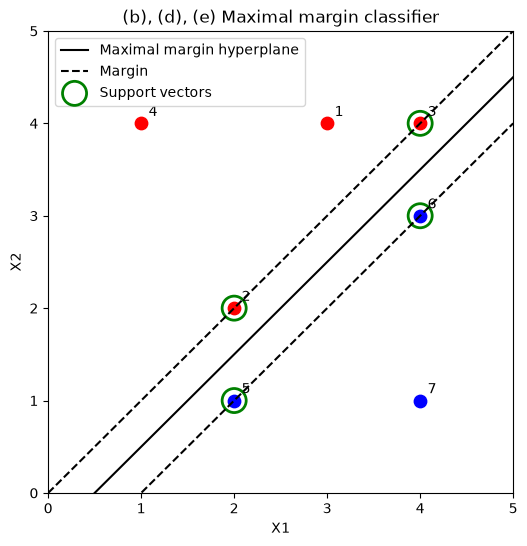

In [68]:
line_x = np.linspace(0, 5, 100)

plt.figure(figsize=(6, 6))
for i in range(7):
    plt.scatter(obs_x1[i], obs_x2[i], color=obs_y[i].lower(), s=80)
    plt.text(obs_x1[i] + 0.08, obs_x2[i] + 0.08, str(i + 1))

plt.plot(line_x, line_x - 0.5, 'k-', label='Maximal margin hyperplane')
plt.plot(line_x, line_x, 'k--', label='Margin')
plt.plot(line_x, line_x - 1, 'k--')

support_x1 = [2, 4, 2, 4]
support_x2 = [2, 4, 1, 3]
plt.scatter(support_x1, support_x2, s=300, facecolors='none', edgecolors='green', linewidths=2, label='Support vectors')

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('(b), (d), (e) Maximal margin classifier')
plt.legend(loc='upper left')
plt.show()

**(f)** Observation 7 is about 1.77 from the hyperplane, well outside the margin, so it is not a support vector. The hyperplane only depends on the support vectors, so a small move of observation 7 does not change it.

**(g)** $-0.6 + 1.1X_1 - X_2 = 0$ separates the classes but with a smaller margin.

**(h)** A red point at (4, 2) lies between blue observations 6 and 7. Any half-plane containing both blue points contains the segment between them, so the classes can no longer be separated.

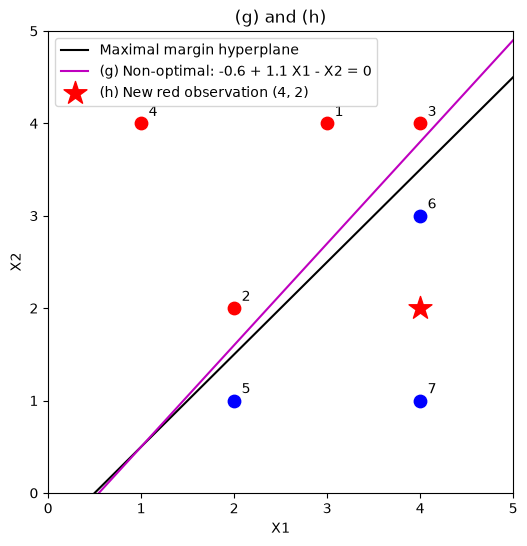

In [69]:
plt.figure(figsize=(6, 6))
for i in range(7):
    plt.scatter(obs_x1[i], obs_x2[i], color=obs_y[i].lower(), s=80)
    plt.text(obs_x1[i] + 0.08, obs_x2[i] + 0.08, str(i + 1))

plt.plot(line_x, line_x - 0.5, 'k-', label='Maximal margin hyperplane')
plt.plot(line_x, 1.1 * line_x - 0.6, 'm-', label='(g) Non-optimal: -0.6 + 1.1 X1 - X2 = 0')
plt.scatter(4, 2, color='red', marker='*', s=300, label='(h) New red observation (4, 2)')

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('(g) and (h)')
plt.legend(loc='upper left')
plt.show()